In this notebook we explore how the biases depend on the redshifts included in the calculation

In [13]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

from IPython.core.display import display, HTML
display(HTML("<style>.container { width:85% !important; }</style>"))

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import matplotlib.pyplot as plt
from cosmoblender import tools as tls
from cosmoblender import qest
from cosmoblender import biases
import os

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [ ]:
textwidth = 6.05 #inches
textheight = textwidth/3 #8.77 #inches

# Decide whether or not to break down the total into contributions from different halos
plot_breakdown = True

plotting_params = {'font.size':8, 'axes.labelsize':8, 'xtick.labelsize':8, 'ytick.labelsize':8, \
                      'font.family':'serif', 'text.usetex':True, 'figure.figsize': [textwidth, textheight],
                   'axes.titlesize':8, 'lines.linewidth':0.7}

plt.rcParams.update(plotting_params)
plots_dir = '/Users/antonbaleatolizancos/Projects/lensing_rec_biases/paper/5f71fb65ea173d000120afc7/'

# Hacky way of typsetting scientific notation
def as_si(x, ndp):
    '''
    From https://stackoverflow.com/questions/31453422/displaying-numbers-with-x-instead-of-e-scientific-notation-in-matplotlib/31453961
    - Inputs:
        * x = number
        * ndp = number of decimal places
    '''
    s = '{x:0.{ndp:d}e}'.format(x=x, ndp=ndp)
    m, e = s.split('e')
    return r'{m:s}\times 10^{{{e:d}}}'.format(m=m, e=int(e))

In [ ]:
# Directory to save to and load cached calculations from
outdir = './cached_calcs/'

In [16]:
# Foreground cleaning? Only relevant if many frequencies are provided
MV_ILC_bool = False 
deproject_CIB = False
deproject_tSZ = False
fg_cleaning_dict = {'MV_ILC_bool':MV_ILC_bool, 'deproject_CIB':deproject_CIB, 'deproject_tSZ':deproject_tSZ}

In [17]:
lmax = 4000
SPT_properties = {'nlev_t': np.array([0.]),
                  'beam_size':np.array([1]), 'lmax':lmax}

In [22]:
# You can specify a cosmological model -- in this case, match Websky
H0 = 68.
cosmoParams = {'As':2.08e-9,'ns':.965,'omch2':(0.31-0.049)*(H0/100.)**2,'ombh2':0.049*(H0/100.)**2,'tau':0.055,'H0':H0}

which_bias = 'tsz'#'cib'

if which_bias == 'cib':
    # For CIB, we found no difference between nz=150 and nz=50 for the prim bispec and trispec, so we run with nz=50 so we can also compute the sec bispec in a reasonable time
    nZs = 50 
    nMasses = 40  #40
    m_min = 1e7

    z_max_array = np.array([7, 6, 5, 4, 3])

elif which_bias == 'tsz':
    # For tSZ we DO find big differences between nz=150 and nz=50 when running up to zmax=7 or so. But further testing reveals that the calculation is fully converged by z=3 or so, so we can run to lower z and get away with lower nz as well
    nZs = 50
    nMasses = 40
    m_min = 1e7

    z_max_array = np.array([3.0,2.5, 2,1.5,1.0,0.5])

# Set CIB halo model
cib_model='viero'

Note that you can typically skip the following cell since arrays are already saved to file

In [8]:
# What maximum halo mass cut to use
mcut_Mvir = None #2e14

if mcut_Mvir is None:
    print('Using no mass cut -- i.e. infinity')
    mcut_str = ''
else:
    print('Using mass cut of Mvir = %s Msun/h'%(as_si(mcut_Mvir,2)))
    mcut_str = '_Mcut%s'%(as_si(mcut_Mvir,2))
print(mcut_str)

Using no mass cut -- i.e. infinity



In [ ]:
#
#
# Calculate the biases
#
#

get_secondary_bispec_bias = True
bin_width_out_second_bispec_bias = 100
parallelise_secondbispec = False

if mcut_Mvir is None:
    experiment = qest.experiment(**SPT_properties, **fg_cleaning_dict, nx_secbispec=256, dx_arcmin_secbispec=0.1)
else:
    experiment = qest.experiment(**SPT_properties, **fg_cleaning_dict, nx_secbispec=256, dx_arcmin_secbispec=0.1, massCut_Mvir=mcut_Mvir)

for i, z_max in enumerate(z_max_array):
    hm_calc = biases.hm_framework(cosmoParams=cosmoParams, nZs=nZs, nMasses=nMasses, cib_model=cib_model, z_max=z_max, m_min=m_min)
    
    if which_bias=='cib':
        hm_calc.get_cib_auto_biases(experiment, get_secondary_bispec_bias=get_secondary_bispec_bias,
                                    parallelise_secondbispec=parallelise_secondbispec,
                                    bin_width_out_second_bispec_bias=bin_width_out_second_bispec_bias)
        experiment.save_biases(output_filename=outdir+'cib_dict_with_biases_z_max{}_nzs{}{}'.format(z_max, nZs, mcut_str))
    elif which_bias=='tsz':
        hm_calc.get_tsz_auto_biases(experiment, get_secondary_bispec_bias=get_secondary_bispec_bias,
                                    parallelise_secondbispec=parallelise_secondbispec,
                                    bin_width_out_second_bispec_bias=bin_width_out_second_bispec_bias)
        experiment.save_biases(output_filename=outdir+'tsz_dict_with_biases_z_max{}_nzs{}{}'.format(z_max, nZs, mcut_str))
    else:
        raise ValueError('which_bias must be cib or tsz')
    print('Completed {}/{}'.format(i+1, len(z_max_array)))

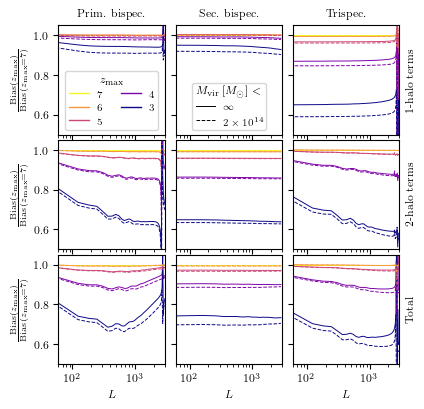

In [ ]:
textwidth = 4

import matplotlib.cm as cm
colors = cm.plasma(np.linspace(1, 0, len(z_max_array)))

assert which_bias in ['cib'], 'which_bias must be cib to run this cell'
foregrounds = np.array(['cib'])

fig, axes = plt.subplots(3, 3, sharex=True, sharey=True, figsize=(1.1*textwidth, 1.1*textwidth), squeeze=True)

[ax.set_title(lab) for ax, lab in zip(axes[0, :], [r'Prim. bispec.', r'Sec. bispec.', r'Trispec.'])]
[ax.set_xlabel(r'$L$') for ax in axes[2, :]]

mcut_strs = ['', '_Mcut2.00\\times 10^{14}']
linestyles = ['-', '--']
labels = [r'$\infty$', r'$2\times 10^{14}$']

for foreground in foregrounds:
    for mcut_str, linestyle, label in zip(mcut_strs, linestyles, labels):
        dict_of_biases_fullcalc = qest.load_dict_of_biases(outdir+'{}_dict_with_biases_z_max{}_nzs{}{}.pkl'.format(foreground, z_max_array[0], nZs, mcut_str))
        for col, bias in enumerate(['prim_bispec', 'second_bispec', 'trispec']):
            try:
                if bias=='second_bispec':
                    ells = dict_of_biases_fullcalc['second_bispec_bias_ells']
                else:
                    ells = dict_of_biases_fullcalc['ells']
                numerator_of_total = np.zeros((len(ells), len(z_max_array)), dtype='complex128')
                denom_of_total = dict_of_biases_fullcalc[foreground][bias]['1h'] + dict_of_biases_fullcalc[foreground][bias]['2h']
                for row, term in enumerate(['1h', '2h','total']):
                    for i, z_max in enumerate(z_max_array):
                        dict_of_biases = qest.load_dict_of_biases(outdir+'{}_dict_with_biases_z_max{}_nzs{}{}.pkl'.format(foreground, z_max, nZs, mcut_str))
                        if term == 'total':
                            total = numerator_of_total[:, i] / denom_of_total
                            axes[row, col].plot(ells, total, color=colors[i], linestyle=linestyle)
                        else:
                            numerator_of_total[:, i] += dict_of_biases[foreground][bias][term]
                            axes[row, col].plot(ells, dict_of_biases[foreground][bias][term] / dict_of_biases_fullcalc[foreground][bias][term], color=colors[i], linestyle=linestyle)
                        plt.gca().set_ylim([0.5, 1.05])
                        plt.gca().set_xlim([60, 3000])
                        plt.gca().set_xscale('log')
            except:
                print(f'no {foreground} {bias} bias (mcut_str={mcut_str})')

[axes[i,0].set_ylabel(r'$\frac{\mathrm{Bias}(z_{\mathrm{max}})}{\mathrm{Bias}(z_{\mathrm{max}}='+str(z_max_array[0])+r')}$') for i in range(3)]

[ax.yaxis.set_label_position("right") for ax in axes[:, 2]]
[ax.set_ylabel(lab) for ax, lab in zip(axes[:, 2], [r'1-halo terms', r'2-halo terms', r'Total'])]

plt.subplots_adjust(hspace=0.05, wspace=0.1)

[axes[0,0].plot([],[], color=colors[i], lw=1, label=z_max_array.astype(int).astype(str)[i]) for i in range(len(z_max_array))]
axes[0,0].legend(title=r'$z_{\rm max}$', fontsize=7, title_fontsize=8, loc='lower center', ncols=2)

for linestyle, label in zip(linestyles, labels):
    axes[0,1].plot([],[], color='k', linestyle=linestyle, label=label)
axes[0,1].legend(title=r'$M_{\rm vir}\,[M_{\odot}]<$', fontsize=7, title_fontsize=8, loc='lower center', ncols=1)

plt.savefig(plots_dir+'cib_convergence_vs_zmax.pdf', bbox_inches='tight', dpi=1000)


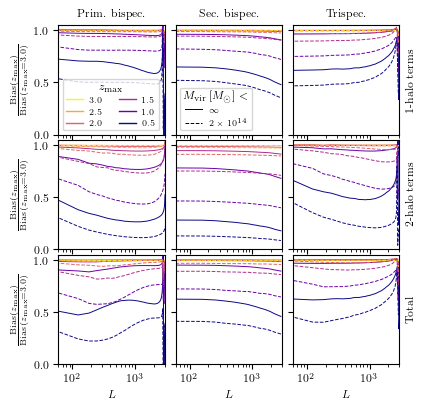

In [ ]:
textwidth = 4

import matplotlib.cm as cm
colors = cm.plasma(np.linspace(1, 0, len(z_max_array)))

assert which_bias in ['tsz'], 'which_bias must be tsz to run this cell'
foregrounds = np.array(['tsz'])

fig, axes = plt.subplots(3, 3, sharex=True, sharey=True, figsize=(1.1*textwidth, 1.1*textwidth), squeeze=True)

[ax.set_title(lab) for ax, lab in zip(axes[0, :], [r'Prim. bispec.', r'Sec. bispec.', r'Trispec.'])]
[ax.set_xlabel(r'$L$') for ax in axes[2, :]]

mcut_strs = ['', '_Mcut2.00\\times 10^{14}']
linestyles = ['-', '--']
labels = [r'$\infty$', r'$2\times 10^{14}$']

for foreground in foregrounds:
    for mcut_str, linestyle, label in zip(mcut_strs, linestyles, labels):
        dict_of_biases_fullcalc = qest.load_dict_of_biases(outdir+'{}_dict_with_biases_z_max{}_nzs{}{}.pkl'.format(foreground, z_max_array[0], nZs, mcut_str))
        for col, bias in enumerate(['prim_bispec', 'second_bispec', 'trispec']):
            try:
                if bias=='second_bispec':
                    ells = dict_of_biases_fullcalc['second_bispec_bias_ells']
                else:
                    ells = dict_of_biases_fullcalc['ells']
                numerator_of_total = np.zeros((len(ells), len(z_max_array)), dtype='complex128')
                denom_of_total = dict_of_biases_fullcalc[foreground][bias]['1h'] + dict_of_biases_fullcalc[foreground][bias]['2h']
                for row, term in enumerate(['1h', '2h','total']):
                    for i, z_max in enumerate(z_max_array):
                        dict_of_biases = qest.load_dict_of_biases(outdir+'{}_dict_with_biases_z_max{}_nzs{}{}.pkl'.format(foreground, z_max, nZs, mcut_str))
                        if term == 'total':
                            total = numerator_of_total[:, i] / denom_of_total
                            axes[row, col].plot(ells, total, color=colors[i], linestyle=linestyle)
                        else:
                            numerator_of_total[:, i] += dict_of_biases[foreground][bias][term]
                            axes[row, col].plot(ells, dict_of_biases[foreground][bias][term] / dict_of_biases_fullcalc[foreground][bias][term], color=colors[i], linestyle=linestyle)

                        plt.gca().set_ylim([0., 1.05])
                        plt.gca().set_xlim([60, 3000])
                        plt.gca().set_xscale('log')
            except:
                print(f'no {foreground} {bias} bias (mcut_str={mcut_str})')

[axes[i,0].set_ylabel(r'$\frac{\mathrm{Bias}(z_{\mathrm{max}})}{\mathrm{Bias}(z_{\mathrm{max}}='+str(z_max_array[0])+r')}$') for i in range(3)]

[ax.yaxis.set_label_position("right") for ax in axes[:, 2]]
[ax.set_ylabel(lab) for ax, lab in zip(axes[:, 2], [r'1-halo terms', r'2-halo terms', r'Total'])]

plt.subplots_adjust(hspace=0.05, wspace=0.1)

[axes[0,0].plot([],[], color=colors[i], lw=1, label=f"{z_max_array[i]:.1f}") for i in range(len(z_max_array))]
axes[0,0].legend(title=r'$z_{\rm max}$', fontsize=6, title_fontsize=8, loc='lower left', ncols=2)

for linestyle, label in zip(linestyles, labels):
    axes[0,1].plot([],[], color='k', linestyle=linestyle, label=label)
axes[0,1].legend(title=r'$M_{\rm vir}\,[M_{\odot}]<$', fontsize=6, title_fontsize=8, loc='lower left', ncols=1)

plt.savefig(plots_dir+'tsz_convergence_vs_zmax.pdf', bbox_inches='tight', dpi=1000)
